# 4 · AlphaZero-style search and self-play

**Notebook 4 of 4** — SFT → REINFORCE → PPO → **MCTS**.

Notebooks 2–3 asked the network to pick good moves *in one forward pass* and
learned from a single, delayed signal (the game result).  AlphaZero changes two
things:

1. **Look ahead.**  At every move a Monte-Carlo Tree Search explores a few
   hundred continuations, using the policy to decide *where* to look and the
   value head to judge positions it doesn't search to the end.
2. **Learn from the search.**  The search's visit distribution π is a better
   policy than the raw network, so we train the network to predict π (plain
   cross-entropy — supervised learning on targets the agent makes itself) and
   the value head to predict the outcome.  Better network → better search →
   better targets.

| | REINFORCE / PPO | AlphaZero |
|---|---|---|
| policy target | the sampled move, weighted by a noisy advantage | full search distribution π over all moves |
| variance | high (one scalar per game) | low (π is a dense target every move) |
| lookahead at play time | none | hundreds of simulations |
| cost | 1 forward pass / move | `sims` forward passes / move |

This notebook produces **`checkpoints/engine.pt`** — the final engine — and
measures its Elo.  **Runtime:** ~1.5 hours on an Apple M4 (most of it self-play).

In [1]:
import sys, json, time, copy
from pathlib import Path
import multiprocessing as mp
import numpy as np, chess, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "train" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "train"))
from chesslib.model import load_checkpoint, save_checkpoint, masked_log_softmax, default_device
from chesslib.mcts import MCTS, Evaluator, SearchConfig, Tree, choose_move
from chesslib.selfplay import SelfPlayConfig, parallel_selfplay, ReplayBuffer
from chesslib.arena import play_match, fit_elo

DEVICE = default_device()
CKPT_DIR, RESULTS = ROOT / "train" / "checkpoints", ROOT / "train" / "results"
torch.manual_seed(0); np.random.seed(0)
START = CKPT_DIR / "sft.pt"
print("device:", DEVICE, "| starting from", START.name)

device: mps | starting from sft.pt


## 1 · Monte-Carlo Tree Search

Each node is a position; each edge a move with statistics `N` (visits), `W`
(total value), `P` (the network's prior).  One **simulation**:

1. **Select** – from the root, repeatedly take the move maximising
   $$Q(s,a) + c_{\text{puct}}\,P(s,a)\,\frac{\sqrt{\sum_b N(s,b)}}{1+N(s,a)}$$
   *exploit* (high mean value `Q = W/N`) vs. *explore* (high prior, few visits).
2. **Expand & evaluate** – at a new position run the network once: priors for
   its moves and a value `V` (instead of playing random moves to the end).
3. **Back up** – add `V` to every edge on the path, **flipping the sign each
   ply** (good for me = bad for you).

After all simulations, the move with the most visits is played (or, early in
self-play, one is *sampled* ∝ visits for variety).  Details that matter in
practice (see `chesslib/mcts.py`):

* **mates and draws are scored exactly**; a repeated position counts as a draw
  inside the tree, so the search doesn't waste visits shuffling;
* **first-play urgency**: unvisited moves are assumed slightly worse than the
  parent, so search concentrates on the policy's best ideas;
* **batching**: many games search simultaneously and their leaves are evaluated
  in one network call (~30× faster than one at a time on the GPU);
* **tree reuse**: after a move, the matching subtree becomes the next root.

### Watch it think

A position where Black has just blundered the queen.  Compare the network's
instinct (prior *P*) with where the search spends its visits:

In [2]:
sft = load_checkpoint(START)
board = chess.Board("rnb1kbnr/pppp1ppp/8/4p1q1/4P3/3P4/PPP2PPP/RNBQKBNR w KQkq - 1 3")
tree = Tree(board.copy())
MCTS(Evaluator(sft, "cpu")).search([tree], 400)
root = tree.root
order = np.argsort(-root.N)[:8]
print(f"{'move':6} {'prior P':>8} {'visits':>7} {'Q':>7}")
for i in order:
    q = root.W[i] / max(root.N[i], 1)
    print(f"{board.san(root.moves[i]):6} {root.P_raw[i]:8.1%} {int(root.N[i]):7d} {q:+7.2f}")
print("root value (side to move):", round(root.q(), 3))

move    prior P  visits       Q
Bxg5      16.8%     358   +0.62
Nf3        6.3%       5   +0.13
Nh3        5.4%       3   -0.03
c4         2.8%       2   +0.09
h4         2.9%       2   +0.03
Nd2        3.3%       2   -0.01
Bd2        2.6%       2   +0.09
Be3        3.0%       2   +0.09
root value (side to move): 0.558


## 2 · Search makes the same network stronger

Before any new training: the SFT network as a raw policy vs. with 32 and 128
simulations per move, all against `ab1` (≈ 1200 Elo on our Stockfish-anchored
scale — see §6).  This is the "test-time compute" knob.

SFT policy vs ab1: +3 =11 -26 (score 21.2%, Elo diff -228 ± 148)


SFT+MCTS(32) vs ab1: +10 =13 -17 (score 41.2%, Elo diff -61 ± 114)


SFT+MCTS(128) vs ab1: +32 =4 -4 (score 85.0%, Elo diff +301 ± 187)


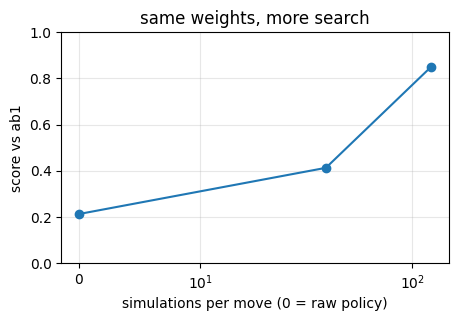

In [3]:
scaling = {}
for sims in [0, 32, 128]:
    spec = ({"type": "policy", "checkpoint": str(START), "label": "SFT policy"} if sims == 0 else
            {"type": "mcts", "checkpoint": str(START), "sims": sims, "label": f"SFT+MCTS({sims})"})
    scaling[sims] = play_match(spec, {"type": "bot", "name": "ab1"}, n_games=40, workers=8, seed=11)
plt.figure(figsize=(5, 3))
plt.plot(list(scaling), [m.score for m in scaling.values()], "o-")
plt.xscale("symlog", linthresh=16); plt.xlabel("simulations per move (0 = raw policy)"); plt.ylabel("score vs ab1")
plt.ylim(0, 1); plt.grid(alpha=.3); plt.title("same weights, more search"); plt.show()

## 3 · The AlphaZero training loop

Each **iteration**:

1. **Self-play** `GAMES_PER_ITER` games with the current best network.  Every
   move: `SIMS` simulations with **Dirichlet noise** on the root priors
   (exploration), sample the move ∝ visits for the first `temp_plies` plies,
   then play the most-visited move.  Store *(position, π, z)*.
2. **Train** on minibatches from a **replay buffer** of recent positions:
   $$\mathcal L = -\sum_a \pi(a)\log p_\theta(a\mid s) \;+\; \mathrm{CE}\big(\text{WDL}_\theta(s), z\big)$$
   No importance ratios, no clipping: the targets are fixed once the game is
   played, so reusing samples is safe (unlike PPO).
3. **Gate**: the new network plays the current best (both with search).  It
   becomes the self-play network only if it scores > 55% — protection against
   an unlucky update making the data worse.

Speed-ups that keep this laptop-sized:

* **Resignation** when the search is sure it is lost (root value < −0.95 twice
  in a row).  In `resign_disable_prob` of games resignation is off, so we can
  check how often a resignation would have been wrong.
* **Warm start** from the SFT network (AlphaZero started from random weights —
  that needs millions of games).
* **Teacher anchor**: half of every training batch is drawn from the SFT
  dataset (the `ab2` games).  With only a few hundred self-play games per
  iteration, pure self-play targets are a small, noisy dataset and the network
  drifts; mixing in the teacher keeps what SFT learned while π pulls it towards
  moves the *search* prefers.

> **How these settings were chosen.**  One batch of 384 self-play games, four
> ways to train on it, each new network played 80 games (both sides searching)
> against the network it started from:
>
> | variant | score vs start | Elo |
> |---|---|---|
> | lr 1e-3 | 50.6% | +4 ± 77 |
> | lr 2e-4 | 55.6% | +39 ± 78 |
> | lr 2e-4, **value head only** (no π loss) | 39.4% | −75 ± 79 |
> | lr 2e-4, **50% teacher data** | 59.4% | +66 ± 79 |
>
> The π targets are what carry the improvement; training only the value head on
> a few hundred noisy game results *hurt*.  A lower learning rate and the teacher
> anchor both helped.  (Error bars overlap — this is a small experiment, but the
> direction was consistent with the full runs.)

In [4]:
ITERATIONS     = 8
GAMES_PER_ITER = 384
WORKERS        = 3            # self-play processes sharing the GPU
SIMS           = 160
BUFFER         = 200_000      # positions (~6 iterations of games)
BATCH, LR      = 512, 2e-4
REPLAY_RATIO   = 2            # each new position is sampled ~this many times
TEACHER_MIX    = 0.5          # fraction of each batch's loss from the SFT (teacher) dataset
GATE_GAMES, GATE_SIMS, GATE_THRESHOLD = 80, 64, 0.55

cfg = SelfPlayConfig(sims=SIMS, concurrent_games=GAMES_PER_ITER // WORKERS, opening_random_plies=4,
                     temp_plies=16, resign_threshold=0.95, resign_disable_prob=0.2, max_plies=300,
                     search=SearchConfig(c_puct=2.0, fpu_reduction=0.25, dirichlet_alpha=0.3, dirichlet_eps=0.25))
print(cfg)

SelfPlayConfig(sims=160, fast_sims=0, full_search_prob=1.0, temp_plies=16, temperature=1.0, max_plies=300, resign_threshold=0.95, resign_disable_prob=0.2, opening_random_plies=4, concurrent_games=128, search=SearchConfig(c_puct=2.0, fpu_reduction=0.25, dirichlet_alpha=0.3, dirichlet_eps=0.25, leaves_per_round=1, virtual_loss=1.0))


In [5]:
from chesslib.data import load_arrays, iterate_batches
teacher_file = sorted((ROOT / "data").glob("sft_*.npz"), key=lambda p: p.stat().st_mtime)[-1]
teacher = load_arrays(teacher_file)            # cached by notebook 1
teacher_idx = np.arange(len(teacher["actions"]))
print("teacher data:", teacher_file.name, f"{len(teacher_idx):,} positions")

def teacher_batches(seed=0):
    while True:
        yield from iterate_batches(teacher, teacher_idx, BATCH // 2, device=DEVICE, seed=seed)
        seed += 1
tb = teacher_batches()

model = load_checkpoint(START).to(DEVICE)
BEST = CKPT_DIR / "mcts.pt"; CAND = CKPT_DIR / "mcts_candidate.pt"
save_checkpoint(BEST, model.cpu(), notebook="chess_mcts", iteration=0, start=START.name); model.to(DEVICE)
buffer = ReplayBuffer(BUFFER)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
pool = mp.get_context("spawn").Pool(WORKERS)
log, best_iter = [], 0

for it in range(1, ITERATIONS + 1):
    t0 = time.time()
    # 1. self-play with the current best network
    best = load_checkpoint(BEST)
    games = parallel_selfplay(best, GAMES_PER_ITER, cfg, workers=WORKERS, seed=it, pool=pool, device=str(DEVICE))
    buffer.add_games(games)
    new_pos = sum(len(g.pi) for g in games)
    t_play = time.time() - t0

    # 2. train the candidate on the replay buffer
    model.train()
    steps = max(50, REPLAY_RATIO * new_pos // BATCH)
    p_sum = v_sum = 0.0
    for _ in range(steps):
        b = buffer.sample(BATCH, DEVICE)
        logits, wdl = model(b["x"])
        p_loss = -(b["pi"] * masked_log_softmax(logits, b["mask"])).sum(1).mean()
        v_loss = F.cross_entropy(wdl, b["wdl"])
        loss = p_loss + v_loss
        if TEACHER_MIX > 0:
            t = next(tb)
            t_logits, t_wdl = model(t["x"])
            t_loss = F.nll_loss(masked_log_softmax(t_logits, t["mask"]), t["action"]) + F.cross_entropy(t_wdl, t["wdl"])
            loss = (1 - TEACHER_MIX) * loss + TEACHER_MIX * t_loss
        opt.zero_grad(); loss.backward(); opt.step()
        p_sum += p_loss.item(); v_sum += v_loss.item()
    model.eval(); save_checkpoint(CAND, model.cpu(), notebook="chess_mcts", iteration=it); model.to(DEVICE)

    # 3. gate: candidate vs best, both searching
    gate = play_match({"type": "mcts", "checkpoint": str(CAND), "sims": GATE_SIMS, "label": f"candidate {it}"},
                      {"type": "mcts", "checkpoint": str(BEST), "sims": GATE_SIMS, "label": f"best ({best_iter})"},
                      n_games=GATE_GAMES, workers=8, seed=1000 + it, verbose=False)
    promoted = gate.score > GATE_THRESHOLD
    if promoted:
        best_iter = it
        save_checkpoint(BEST, model.cpu(), notebook="chess_mcts", iteration=it, start=START.name); model.to(DEVICE)

    fr = [g.false_resign() for g in games if g.false_resign() is not None]
    entry = {"iter": it, "games": len(games), "positions": new_pos, "buffer": len(buffer),
             "avg_plies": float(np.mean([g.plies for g in games])),
             "resigned": sum(g.resigned for g in games),
             "false_resign_rate": float(np.mean(fr)) if fr else None,
             "decisive": sum(g.result != "1/2-1/2" for g in games) / len(games),
             "policy_loss": p_sum / steps, "value_loss": v_sum / steps, "steps": steps,
             "gate_score": gate.score, "promoted": promoted, "best_iter": best_iter,
             "selfplay_s": t_play, "total_s": time.time() - t0}
    log.append(entry)
    print(f"iter {it:2d} | {len(games)} games {new_pos:,} pos ({t_play:.0f}s), {entry['avg_plies']:.0f} plies, "
          f"{entry['resigned']} resigned | p {entry['policy_loss']:.3f} v {entry['value_loss']:.3f} | "
          f"gate {gate.wins}-{gate.draws}-{gate.losses} ({gate.score:.0%}){' → promoted' if promoted else ''} | "
          f"{entry['total_s']/60:.1f} min", flush=True)

pool.terminate(); pool.join()

teacher data: sft_ab2_6000.npz 746,155 positions


iter  1 | 384 games 33,693 pos (546s), 91 plies, 191 resigned | p 2.030 v 0.719 | gate 30-34-16 (59%) → promoted | 10.6 min


iter  2 | 384 games 33,082 pos (544s), 90 plies, 188 resigned | p 2.044 v 0.691 | gate 25-28-27 (49%) | 10.6 min


iter  3 | 384 games 34,944 pos (613s), 95 plies, 174 resigned | p 2.046 v 0.701 | gate 21-37-22 (49%) | 11.8 min


iter  4 | 384 games 33,277 pos (561s), 90 plies, 174 resigned | p 2.051 v 0.698 | gate 35-27-18 (61%) → promoted | 10.5 min


iter  5 | 384 games 33,524 pos (443s), 91 plies, 154 resigned | p 2.046 v 0.696 | gate 25-32-23 (51%) | 8.6 min


iter  6 | 384 games 34,442 pos (456s), 93 plies, 172 resigned | p 2.044 v 0.692 | gate 24-38-18 (54%) | 8.9 min


iter  7 | 384 games 35,256 pos (440s), 95 plies, 150 resigned | p 2.041 v 0.727 | gate 28-32-20 (55%) | 8.7 min


iter  8 | 384 games 33,465 pos (449s), 91 plies, 162 resigned | p 2.040 v 0.736 | gate 27-27-26 (51%) | 8.6 min


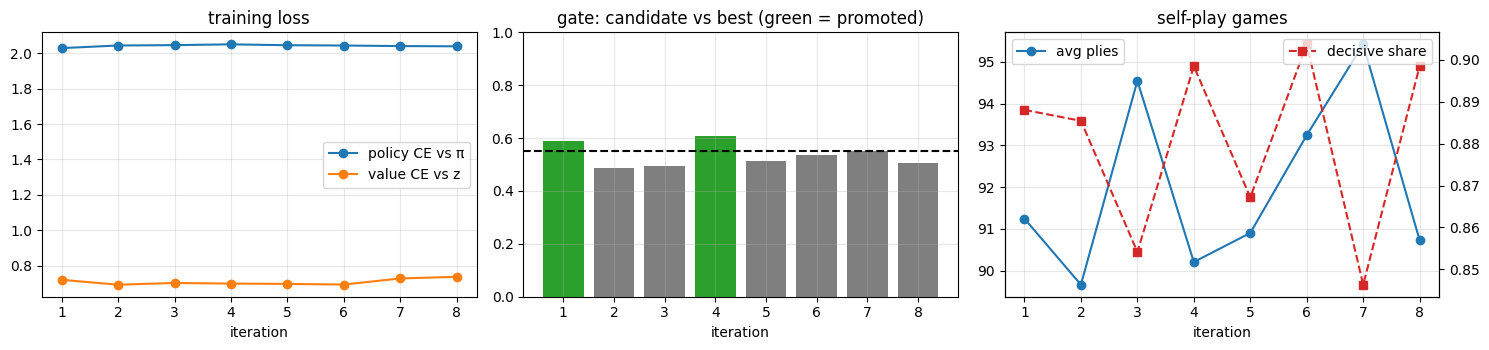

best network from iteration 4


In [6]:
it = [e["iter"] for e in log]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(it, [e["policy_loss"] for e in log], "o-", label="policy CE vs π")
ax[0].plot(it, [e["value_loss"] for e in log], "o-", label="value CE vs z"); ax[0].legend(); ax[0].set_title("training loss")
ax[1].bar(it, [e["gate_score"] for e in log], color=["tab:green" if e["promoted"] else "tab:gray" for e in log])
ax[1].axhline(GATE_THRESHOLD, ls="--", c="k"); ax[1].set_ylim(0, 1); ax[1].set_title("gate: candidate vs best (green = promoted)")
ax[2].plot(it, [e["avg_plies"] for e in log], "o-", label="avg plies")
ax2 = ax[2].twinx(); ax2.plot(it, [e["decisive"] for e in log], "s--", c="tab:red", label="decisive share")
ax[2].set_title("self-play games"); ax[2].legend(loc="upper left"); ax2.legend(loc="upper right")
for a in ax: a.set_xlabel("iteration"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("best network from iteration", best_iter)

## 4 · Did self-play help?

The gate says "better than the previous best", but with a 60-game gate a 55%
score is within noise.  The honest test: the final best network against the
**starting** SFT network, both with the same search budget.

In [7]:
vs_start = play_match({"type": "mcts", "checkpoint": str(BEST), "sims": 128, "label": f"AZ best (iter {best_iter})"},
                      {"type": "mcts", "checkpoint": str(START), "sims": 128, "label": "SFT start"},
                      n_games=100, workers=8, seed=77)

AZ best (iter 4) vs SFT start: +42 =31 -27 (score 57.5%, Elo diff +53 ± 70)


## 5 · The final engine

`engine.pt` = the best network; at play time it searches `ENGINE_SIMS`
simulations per move (~0.3 s on one CPU core).  It can be played in the app as
the `engine` bot.

In [8]:
ENGINE_SIMS = 200
engine = load_checkpoint(BEST)
save_checkpoint(CKPT_DIR / "engine.pt", engine, notebook="chess_mcts", iteration=best_iter, sims=ENGINE_SIMS,
                start=START.name)
ENGINE = {"type": "mcts", "checkpoint": str(CKPT_DIR / "engine.pt"), "sims": ENGINE_SIMS, "label": "engine"}
print("saved", CKPT_DIR / "engine.pt")

saved /Users/connorswanson/Desktop/projects/chessEngine/train/checkpoints/engine.pt


## 6 · How strong is it?  Elo against fixed anchors

Elo is relative, so we need opponents with known ratings.  Stockfish's
`UCI_LimitStrength` mode is calibrated to human-like ratings; its lowest
setting is 1320.  We give it 0.1 s per move.  Against these anchors (measured
in the same way), our scripted bots come out at roughly **ab1 ≈ 1200,
ab2 ≈ 1470, ab3 ≈ 1670** (±~140).

A player rated 1000 is expected to score ~13% against 1320 and ~24% against
1200.  We play 100 games against Stockfish-1320 and 60 against each bot, then
fit one rating to the Stockfish result (the anchor we trust) and show the bot
results as a cross-check.

> Treat the number as ±100 Elo or so: Stockfish's weakening is calibrated at
> longer time controls, and 100 games is still a small sample.

In [9]:
final = {}
final["sf1320"] = play_match(ENGINE, {"type": "stockfish", "elo": 1320, "movetime": 0.1}, n_games=100, workers=8, seed=500)
for name in ["ab1", "ab2"]:
    final[name] = play_match(ENGINE, {"type": "bot", "name": name}, n_games=60, workers=8, seed=501)
elo, ci = fit_elo([(1320, final["sf1320"])])
elo_bots, ci_bots = fit_elo([(1200, final["ab1"]), (1470, final["ab2"])])
print(f"\nEngine Elo (Stockfish-1320 anchor): {elo:.0f} ± {ci:.0f}")
print(f"Cross-check from ab1/ab2 results:   {elo_bots:.0f} ± {ci_bots:.0f}")

engine vs stockfish(elo=1320,movetime=0.1): +69 =5 -26 (score 71.5%, Elo diff +160 ± 77)


engine vs ab1: +50 =2 -8 (score 85.0%, Elo diff +301 ± 140)


engine vs ab2: +47 =3 -10 (score 80.8%, Elo diff +250 ± 122)

Engine Elo (Stockfish-1320 anchor): 1480 ± 75
Cross-check from ab1/ab2 results:   1643 ± 86


### All four notebooks side by side

Each notebook's network as a **raw policy** (no search) against `ab1`, plus the
final engine with search.  This isolates what each *training method* bought.

In [10]:
rows = []
for name in ["sft", "reinforce", "ppo", "mcts"]:
    path = CKPT_DIR / f"{name}.pt"
    if path.exists():
        m = play_match({"type": "policy", "checkpoint": str(path), "label": f"{name} policy"},
                       {"type": "bot", "name": "ab1"}, n_games=60, workers=8, seed=900, verbose=False)
        rows.append((f"{name} (raw policy)", m))
rows.append((f"engine (MCTS {ENGINE_SIMS})", final["ab1"]))
print(f"{'model':24} {'vs ab1':>14} {'score':>7} {'Elo vs ab1':>11}")
for name, m in rows:
    d, c = m.elo_diff()
    print(f"{name:24} {f'+{m.wins} ={m.draws} -{m.losses}':>14} {m.score:7.1%} {d:+8.0f} ±{c:.0f}")

model                            vs ab1   score  Elo vs ab1
sft (raw policy)             +4 =10 -46   15.0%     -301 ±140
reinforce (raw policy)       +5 =18 -37   23.3%     -207 ±111
ppo (raw policy)             +7 =15 -38   24.2%     -199 ±109
mcts (raw policy)            +7 =18 -35   26.7%     -176 ±104
engine (MCTS 200)             +50 =2 -8   85.0%     +301 ±140


In [11]:
summary = {"elo": elo, "elo_ci": ci, "elo_bots": elo_bots, "best_iter": best_iter, "engine_sims": ENGINE_SIMS,
           "log": log, "vs_start": {"W": vs_start.wins, "D": vs_start.draws, "L": vs_start.losses},
           "final": {k: {"W": m.wins, "D": m.draws, "L": m.losses, "score": m.score, "terminations": m.terminations}
                     for k, m in final.items()},
           "raw_policy_vs_ab1": {n: m.score for n, m in rows}}
(RESULTS / "mcts.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps({k: summary[k] for k in ["elo", "elo_ci", "elo_bots", "best_iter"]}, indent=2))

{
  "elo": 1480.0,
  "elo_ci": 75.0,
  "elo_bots": 1643.0,
  "best_iter": 4
}


## 7 · Takeaways

**Strong**
* **Lookahead.**  The same weights play far better with search (§2) — the
  network only needs good *intuition*; tactics are found by calculation.
* **Low-variance learning.**  π is a dense, per-move target produced by the
  agent itself, so training is ordinary supervised learning on fresh data —
  no ratios, clips or baselines.
* **No teacher ceiling.**  Self-play can in principle exceed the bots that
  produced the SFT data; how far it gets is mostly a matter of compute.

**Weak**
* **Compute.**  Every move costs `SIMS` network evaluations.  This run used
  roughly `ITERATIONS × GAMES_PER_ITER` ≈ 3,000 games; AlphaZero used 44 million.
  Self-play is the bottleneck and dominated this notebook's runtime.
* **Slow feedback.**  Gains per iteration are small and noisy (see the gate
  scores); you need a careful, many-game evaluation to know if you improved.
* **Engineering.**  Batching, sign conventions, terminal handling, tree reuse
  and resignation all have to be right — a sign error silently trains an engine
  that tries to lose.

* **Self-play data is precious and noisy.**  With little of it, the network
  needs an anchor (the teacher data here) — pure AlphaZero gets away without one
  only because it plays millions of games.

**Where to go next**: more iterations and simulations, a bigger network,
playout-cap randomisation (`SelfPlayConfig.fast_sims`), and gradually lowering
`TEACHER_MIX` as self-play data accumulates.